In [1]:
import pandas as pd
import pymysql
import os
import re
import matplotlib.pyplot as plt
import numpy as np

co_p = pymysql.connect(
    host=os.environ['MdB_HOST'],
    db=os.environ['MdB_DBp'],
    user=os.environ['MdB_USER'],
    passwd=os.environ['MdB_PASSWD'])

co_s = pymysql.connect(
    host=os.environ["MdB_HOST"],
    db=os.environ["MdB_DBs"],
    user=os.environ["MdB_USER"],
    passwd=os.environ["MdB_PASSWD"])

In [2]:
def sql(query, params=None, co=co_p):
    return pd.read_sql(query, co, params=params)

In [3]:
def describe_table(table_name, co=co_p):
    query = f"DESCRIBE {table_name}"
    return sql(query, co=co)

In [4]:
def normalize_to_halpha(df, line_names):
    df = df.copy()

    candidates = ["H__1__6563A", "HI_6563"]
    
    halpha_col = None

    for c in candidates:
        if c in df.columns:
            halpha_col = c
            break
    
    halpha = df[halpha_col].copy()
    df["Halpha_raw"] = halpha

    for line in line_names:
        df[line] = df[line] / halpha

    return df 

In [5]:
def get_columns(table_name, co):
    desc = sql(f"DESCRIBE {table_name}", co=co)
    return desc["Field"].tolist()

In [6]:
def wavelength_from_column_name(col):
    m = re.search(r"(\d+(?:\.\d+)?)$", col)

    if m is None:
        return np.nan

    return float(m.group(1))

In [7]:
target_lines = {
    "Hbeta": 4861.33,
    "OIII_4959": 4958.91,
    "OIII_5007": 5006.84,
    "HeI_5876": 5875.62,
    "NII_6548": 6548.05,
    "Halpha": 6562.80,
    "NII_6584": 6583.45,
    "SII_6717": 6716.44,
    "SII_6731": 6730.82,
    "OI_6300": 6300.00}

In [8]:
tables = sql("SHOW TABLES")
tables_s = sql("SHOW TABLES", co=co_s)

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


In [9]:
print(tables)
print(tables_s)

  Tables_in_3MdB
0          abion
1          lines
2        procIDs
3           seds
4            tab
5          teion
6          temis
7         v_3MdB
    Tables_in_3MdBs
0        abundances
1           emis_IR
2          emis_UVA
3          emis_UVB
4          emis_UVC
5           emis_VI
6      ion_col_dens
7          ion_dens
8          ion_frac
9          ion_temp
10  model_directory
11         projects
12     shock_params


In [10]:
print(describe_table("tab", co_p))
print(describe_table("`lines`", co_p))

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


              Field         Type Null  Key Default           Extra
0                 N   bigint(20)   NO  PRI     NaN  auto_increment
1              user  varchar(40)   NO  MUL                        
2    date_submitted     datetime  YES          NaN                
3      date_running     datetime  YES          NaN                
4               ref  varchar(40)   NO  MUL                        
..              ...          ...  ...  ...     ...             ...
510  MIPS_1600M_rad       double   NO            0                
511  IRAC_3600M_rad       double   NO            0                
512  IRAC_4500M_rad       double   NO            0                
513  IRAC_5800M_rad       double   NO            0                
514  IRAC_8000M_rad       double   NO            0                

[515 rows x 6 columns]
    Field         Type Null  Key Default           Extra
0      Nl   bigint(20)   NO  PRI     NaN  auto_increment
1   label  varchar(15)  YES          NaN                
2

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


In [11]:
lines_p = sql('''
SELECT DISTINCT label, lambda
FROM `lines`
ORDER BY lambda
''', co=co_p)

matches = []

for target_name, target_lambda in target_lines.items():
    lines_p["diff"] = abs(lines_p["lambda"] - target_lambda)

    best_match = lines_p.sort_values("diff").iloc[0]

    matches.append({
        "target_name": target_name,
        "target_lambda": target_lambda,
        "matched_label": best_match["label"],
        "matched_lambda": best_match["lambda"],
        "difference": best_match["diff"]})

matches_df = pd.DataFrame(matches)
matched_labels = matches_df["matched_label"].tolist()
print(matches_df)

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


  target_name  target_lambda matched_label  matched_lambda  difference
0       Hbeta        4861.33   H__1__4861A          4861.0        0.33
1   OIII_4959        4958.91   O__3__4959A          4959.0        0.09
2   OIII_5007        5006.84   O__3__5007A          5007.0        0.16
3    HeI_5876        5875.62   HE_1__5876A          5876.0        0.38
4    NII_6548        6548.05   N__2__6548A          6548.0        0.05
5      Halpha        6562.80   H__1__6563A          6563.0        0.20
6    NII_6584        6583.45   N__2__6584A          6584.0        0.55
7    SII_6717        6716.44   S_II__6716A          6716.0        0.44
8    SII_6731        6730.82   S_II__6731A          6731.0        0.18
9     OI_6300        6300.00   O__1__6300A          6300.0        0.00


In [12]:
query_hii = f"""
    SELECT
    N AS model_id,{", ".join(f"`{label}`" for label in matched_labels)}
    FROM tab
    WHERE ref = 'HII_CHIm'
      AND com1 = 'O'
      AND NITROGEN-OXYGEN BETWEEN -0.825 AND -0.625
    """

hii_raw = sql(query_hii)
print(hii_raw.head())
print(hii_raw.shape)

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


   model_id   H__1__4861A   O__3__4959A   O__3__5007A   HE_1__5876A  \
0   2499617  2.758385e+58  3.764294e+57  1.133062e+58  2.109266e+57   
1   2499606  4.566772e+58  3.262531e+58  9.819971e+58  3.328889e+57   
2   2499570  9.076751e+57  3.900287e+56  1.173989e+57  6.811130e+56   
3   2499560  8.851461e+57  4.839619e+57  1.456725e+58  6.021345e+56   
4   2499552  8.916242e+57  3.333338e+57  1.003329e+58  6.301631e+56   

    N__2__6548A   H__1__6563A   N__2__6584A   S_II__6716A   S_II__6731A  \
0  1.069925e+58  8.465943e+58  3.157417e+58  7.108542e+57  5.493283e+57   
1  1.105968e+58  1.369624e+59  3.263721e+58  9.645473e+57  7.413601e+57   
2  5.452239e+57  2.774818e+58  1.608982e+58  4.591533e+57  3.542959e+57   
3  3.784734e+57  2.585841e+58  1.116910e+58  3.842695e+57  2.935979e+57   
4  6.430471e+57  2.635354e+58  1.897622e+58  5.163994e+57  3.947450e+57   

    O__1__6300A  
0  1.254007e+57  
1  2.237343e+57  
2  7.298860e+56  
3  1.078073e+57  
4  1.340223e+57  
(451, 11)


In [13]:
sql("""
SELECT DISTINCT dens
FROM tab
WHERE ref = 'PNe_2014'
ORDER BY dens
""")

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


,dens
0,0.000000
1,1.477121
2,2.000000
3,2.477121
4,3.000000
5,3.477121
6,4.000000
7,4.477121
8,5.000000
9,5.477121


In [14]:
query_pne = f"""
SELECT
    N AS model_id,
    dens,
    radius,
    lumi,
    {", ".join(f"`{label}`" for label in matched_labels)}
FROM tab
WHERE ref = 'PNe_2014'
  AND com1 = 'TR'
  AND com5 = 'D'
  AND com4 = 'L'
  AND com3 = 'M40'
  AND (dens BETWEEN 1.47 AND 1.48 OR dens BETWEEN 1.99 AND 2.01 OR dens BETWEEN 2.47 AND 2.48)
  AND (radius BETWEEN 16.99 AND 17.01 OR radius BETWEEN 17.47 AND 17.48)
"""

pne_raw = sql(query_pne)

print(pne_raw.head())
print(pne_raw.shape)

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


   model_id      dens  radius      lumi   H__1__4861A   O__3__4959A  \
0   1804784  1.477121    17.0  2.301030  4.510484e+33  7.070332e+33   
1   1805503  2.477121    17.0  3.477121  3.662684e+34  1.272889e+35   
2   1805825  2.477121    17.0  3.477121  3.410701e+34  1.201232e+35   
3   1810816  2.000000    17.0  3.477121  3.993994e+34  1.251325e+35   
4   1810901  2.000000    17.0  3.477121  5.089394e+34  1.474236e+35   

    O__3__5007A   HE_1__5876A   N__2__6548A   H__1__6563A   N__2__6584A  \
0  2.128186e+34  6.158038e+32  5.714450e+33  1.316693e+34  1.686360e+34   
1  3.831423e+35  5.162444e+33  3.330713e+33  1.046630e+35  9.828894e+33   
2  3.615693e+35  2.952668e+33  3.545434e+33  9.707328e+34  1.046214e+34   
3  3.766477e+35  5.541417e+33  6.486315e+33  1.147259e+35  1.914226e+34   
4  4.437287e+35  3.489867e+33  2.948308e+34  1.474769e+35  8.700266e+34   

    S_II__6716A   S_II__6731A   O__1__6300A  
0  2.251035e+33  1.628794e+33  5.901210e+32  
1  1.510365e+33  1.393098e+33 

In [15]:
sql("""
SELECT DISTINCT com2
FROM tab
WHERE ref = 'DIG_HR'
ORDER BY com2
""")

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


,com2
0,phi_OB = 3.50
1,phi_OB = 3.75
2,phi_OB = 4.00
3,phi_OB = 4.25
4,phi_OB = 4.50
5,phi_OB = 4.75
6,phi_OB = 5.00
7,phi_OB = 5.25
8,phi_OB = 5.50
9,phi_OB = 5.75


In [16]:
sql("""
SELECT com1, COUNT(*) AS n
FROM tab
WHERE ref = 'DIG_HR'
GROUP BY com1
ORDER BY com1
""")

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


,com1,n
0,logU = -3.0,3757
1,logU = -3.1,3757
2,logU = -3.2,3757
3,logU = -3.3,3757
4,logU = -3.4,3757
5,logU = -3.5,3757
6,logU = -3.6,3757
7,logU = -3.7,3757
8,logU = -3.8,3757
9,logU = -3.9,3757


In [17]:
query_dig = f"""
    SELECT
        N AS model_id,
        {", ".join(f"`{label}`" for label in matched_labels)}
    FROM tab
    WHERE ref = 'DIG_HR'
        AND com3 IN ('N/O = -1.1', 'N/O = -0.9', 'N/O = -0.8', 'N/O = -0.7', 'N/O = -0.6')
        AND com2 IN ('phi_OB = 3.50', 'phi_OB = 3.75', 'phi_OB = 4.00', 'phi_OB = 4.25', 'phi_OB = 4.50', 'phi_OB = 4.75', 'phi_OB = 5.00')
        AND OXYGEN BETWEEN -4.3 AND -2.7
    """

dig_raw = sql(query_dig)

print(dig_raw.head())
print(dig_raw.shape)

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


   model_id   H__1__4861A   O__3__4959A   O__3__5007A   HE_1__5876A  \
0   2450887  9.861405e+53  1.396352e+53  4.202833e+53  1.191194e+53   
1   2450895  5.357001e+53  3.299229e+53  9.930842e+53  6.572256e+52   
2   2450899  4.848448e+53  6.034467e+53  1.816390e+54  5.950621e+52   
3   2450906  4.735369e+53  3.799434e+53  1.143662e+54  6.336824e+52   
4   2450916  4.391147e+53  6.256722e+53  1.883252e+54  5.864620e+52   

    N__2__6548A   H__1__6563A   N__2__6584A   S_II__6716A   S_II__6731A  \
0  1.775677e+53  2.912130e+54  5.239806e+53  4.852588e+53  3.394297e+53   
1  1.641782e+53  1.588039e+54  4.844679e+53  4.318206e+53  3.021581e+53   
2  2.816615e+53  1.428762e+54  8.311966e+53  4.605588e+53  3.219942e+53   
3  5.040054e+53  1.397561e+54  1.487319e+54  9.066332e+53  6.303939e+53   
4  3.064955e+53  1.306578e+54  9.044414e+53  6.653657e+53  4.619135e+53   

    O__1__6300A  
0  1.054096e+53  
1  1.076659e+53  
2  1.120043e+53  
3  2.351264e+53  
4  1.586258e+53  
(6545, 11)


In [18]:
print(hii_raw.isna().sum())
print(hii_raw.head())
print(hii_raw.shape)

print(pne_raw.isna().sum())
print(pne_raw.shape)

print(dig_raw.isna().sum())
print(dig_raw.shape)

model_id       0
H__1__4861A    0
O__3__4959A    0
O__3__5007A    0
HE_1__5876A    0
N__2__6548A    0
H__1__6563A    0
N__2__6584A    0
S_II__6716A    0
S_II__6731A    0
O__1__6300A    0
dtype: int64
   model_id   H__1__4861A   O__3__4959A   O__3__5007A   HE_1__5876A  \
0   2499617  2.758385e+58  3.764294e+57  1.133062e+58  2.109266e+57   
1   2499606  4.566772e+58  3.262531e+58  9.819971e+58  3.328889e+57   
2   2499570  9.076751e+57  3.900287e+56  1.173989e+57  6.811130e+56   
3   2499560  8.851461e+57  4.839619e+57  1.456725e+58  6.021345e+56   
4   2499552  8.916242e+57  3.333338e+57  1.003329e+58  6.301631e+56   

    N__2__6548A   H__1__6563A   N__2__6584A   S_II__6716A   S_II__6731A  \
0  1.069925e+58  8.465943e+58  3.157417e+58  7.108542e+57  5.493283e+57   
1  1.105968e+58  1.369624e+59  3.263721e+58  9.645473e+57  7.413601e+57   
2  5.452239e+57  2.774818e+58  1.608982e+58  4.591533e+57  3.542959e+57   
3  3.784734e+57  2.585841e+58  1.116910e+58  3.842695e+57  2.935979e+57  

In [19]:
hii = normalize_to_halpha(hii_raw, matched_labels)
hii["class"] = "HII"
pne = normalize_to_halpha(pne_raw, matched_labels)
pne["class"] = "PN"
dig = normalize_to_halpha(dig_raw, matched_labels)
dig["class"] = "DIG"

In [20]:
print(hii.head())
print(hii["H__1__6563A"].describe())

   model_id  H__1__4861A  O__3__4959A  O__3__5007A  HE_1__5876A  N__2__6548A  \
0   2499617     0.325821     0.044464     0.133838     0.024915     0.126380   
1   2499606     0.333432     0.238206     0.716983     0.024305     0.080750   
2   2499570     0.327112     0.014056     0.042309     0.024546     0.196490   
3   2499560     0.342305     0.187158     0.563347     0.023286     0.146364   
4   2499552     0.338332     0.126485     0.380719     0.023912     0.244008   

   H__1__6563A  N__2__6584A  S_II__6716A  S_II__6731A  O__1__6300A class  
0          1.0     0.372955     0.083966     0.064887     0.014812   HII  
1          1.0     0.238293     0.070424     0.054129     0.016335   HII  
2          1.0     0.579851     0.165471     0.127683     0.026304   HII  
3          1.0     0.431933     0.148605     0.113541     0.041691   HII  
4          1.0     0.720063     0.195951     0.149788     0.050856   HII  
count    451.0
mean       1.0
std        0.0
min        1.0
25%      

In [21]:
print("HII:", hii.shape)
print("PN :", pne.shape)
#print(pne["H__1__4861A"].describe())
#print(pne["O__3__5007A"].describe())
print("DIG:", dig.shape)
#print(dig["H__1__4861A"].describe())
#print(dig["O__3__5007A"].describe())

HII: (451, 12)
PN : (216, 15)
DIG: (6545, 12)


In [22]:
print(describe_table("emis_VI", co=co_s).head(20))
print(describe_table("shock_params", co=co_s).head(20))
print(describe_table("abundances", co=co_s).head(20))

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


         Field         Type Null  Key Default Extra
0      ModelID   bigint(20)  YES  MUL    None      
1          ref  varchar(40)  YES         None      
2   model_type  varchar(40)  YES         None      
3   Hbeta_Flux       double  YES         None      
4    AlII_3901       double  YES         None      
5   ArIII_3005       double  YES         None      
6   ArIII_3109       double  YES         None      
7   ArIII_5192       double  YES         None      
8   ArIII_7136       double  YES         None      
9    ArIV_4711       double  YES         None      
10   ArIV_4740       double  YES         None      
11   ArIV_7171       double  YES         None      
12   ArIV_7238       double  YES         None      
13   ArIV_7263       double  YES         None      
14   ArIV_7332       double  YES         None      
15    ArV_4625       double  YES         None      
16    ArV_6435       double  YES         None      
17    ArV_7006       double  YES         None      
18  ArXIV_44

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)
/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


        Field        Type Null  Key Default           Extra
0   ALUMINIUM      double  YES         None                
1       ARGON      double  YES         None                
2     AbundID  bigint(20)   NO  PRI    None  auto_increment
3   BERYLLIUM      double  YES         None                
4       BORON      double  YES         None                
5     CALCIUM      double  YES         None                
6      CARBON      double  YES         None                
7    CHLORINE      double  YES         None                
8    CHROMIUM      double  YES         None                
9      COBALT      double  YES         None                
10     COPPER      double  YES         None                
11   FLUORINE      double  YES         None                
12     HELIUM      double  YES         None                
13   HYDROGEN      double  YES         None                
14       IRON      double  YES         None                
15    LITHIUM      double  YES         N

In [23]:
sql('''
SELECT DISTINCT name
FROM abundances
ORDER BY name
''', co=co_s)

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


,name
0,3MdB-PNe2014-solar
1,Allen2008_Dopita2005
2,Allen2008_LMC
3,Allen2008_SMC
4,Allen2008_Solar
5,Allen2008_TwiceSolar
6,Gutkin16_ISM0d0001_C0d26
7,Gutkin16_ISM0d0001_C1d00
8,Gutkin16_ISM0d0002_C0d26
9,Gutkin16_ISM0d0002_C1d00


In [24]:
emis_vi_columns = get_columns("emis_VI", co_s)

shock_lines = []

for col in emis_vi_columns:
    lam = wavelength_from_column_name(col)

    if np.isfinite(lam):
        shock_lines.append({
            "label": col,
            "lambda": lam})

shock_lines = pd.DataFrame(shock_lines).sort_values("lambda")

print(shock_lines.to_string())

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


              label  lambda
23     CII_4267d001     1.0
24      CII_4267d14    14.0
322   FeIV_4869d015    15.0
30     CII_6578d052    52.0
31     CII_6578d053    53.0
664   NeII_3713d079    79.0
665   NeII_3713d082    82.0
191   FeII_3277d083    83.0
197   FeII_3455d114   114.0
192   FeII_3277d116   116.0
100  FeIII_3335d121   121.0
320   FeIV_4868d161   161.0
566    HeI_7065d179   179.0
107  FeIII_3366d206   206.0
661   NeII_3694d213   213.0
662   NeII_3694d214   214.0
323   FeIV_4869d228   228.0
353   FeIV_7191d228   228.0
567    HeI_7065d249   249.0
25     CII_4267d261   261.0
642   NeII_3214d329   329.0
465    FeV_3911d332   332.0
235   FeII_4515d333   333.0
220   FeII_4347d356   356.0
102  FeIII_3355d393   393.0
177   FeII_3187d401   401.0
404   FeVI_3847d401   401.0
416   FeVI_4972d475   475.0
103  FeIII_3355d484   484.0
614     NI_3467d543   543.0
183   FeII_3227d575   575.0
615     NI_3467d617   617.0
198   FeII_3455d636   636.0
551    HeI_3889d643   643.0
552    HeI_3889d646 

In [25]:
matches_s = []

for target_name, target_lambda in target_lines.items():
    shock_lines["diff"] = abs(shock_lines["lambda"] - target_lambda)

    best_match = shock_lines.sort_values("diff").iloc[0]

    matches_s.append({
        "target_name": target_name,
        "target_lambda": target_lambda,
        "matched_label": best_match["label"],
        "matched_lambda": best_match["lambda"],
        "difference": best_match["diff"]})

matches_s_df = pd.DataFrame(matches_s)

In [26]:
print("Shock DB line matches:")
print(matches_s_df)

Shock DB line matches:
  target_name  target_lambda matched_label  matched_lambda  difference
0       Hbeta        4861.33       HI_4861          4861.0        0.33
1   OIII_4959        4958.91     OIII_4959          4959.0        0.09
2   OIII_5007        5006.84     FeII_5007          5007.0        0.16
3    HeI_5876        5875.62     FeVI_5876          5876.0        0.38
4    NII_6548        6548.05      NII_6548          6548.0        0.05
5      Halpha        6562.80       HI_6563          6563.0        0.20
6    NII_6584        6583.45      NII_6583          6583.0        0.45
7    SII_6717        6716.44      SII_6716          6716.0        0.44
8    SII_6731        6730.82      SII_6731          6731.0        0.18
9     OI_6300        6300.00       OI_6300          6300.0        0.00


In [27]:
mapping = {
    'FeII_5007': 'OIII_5007',
    'FeVI_5876': 'HeI_5876'
}

matches_s_df ['matched_label'] = matches_s_df ['matched_label'].replace(mapping)
matched_labels_s = matches_s_df["matched_label"].tolist()
print(matched_labels_s)

['HI_4861', 'OIII_4959', 'OIII_5007', 'HeI_5876', 'NII_6548', 'HI_6563', 'NII_6583', 'SII_6716', 'SII_6731', 'OI_6300']


In [28]:
mag_values = [0.0001, 0.5, 1, 2, 3.23, 4, 5, 10]
vel_values = list(range(100, 1001, 25))

query_snr = f"""
SELECT
    e.ModelID AS model_id,
    a.name AS ref,
    {", ".join(f"e.`{label}`" for label in matched_labels_s)}
FROM shock_params sp
INNER JOIN emis_VI e ON e.ModelID = sp.ModelID
INNER JOIN abundances a ON a.AbundID = sp.AbundID
WHERE e.model_type = 'shock'
  AND sp.ref = 'Allen08'
  AND a.name = 'Allen2008_LMC'
  AND sp.preshck_dens = 1
  AND sp.mag_fld IN ({", ".join(map(str, mag_values))})
  AND sp.shck_vel IN ({", ".join(map(str, vel_values))})
"""

snr_raw = sql(query_snr, co=co_s)

print(snr_raw.head())
print(snr_raw.shape)

/var/folders/h8/4z3pmwq12zlgg94hgcgq904h0000gn/T/ipykernel_7284/236656000.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  return pd.read_sql(query, co, params=params)


   model_id            ref   HI_4861  OIII_4959  OIII_5007  HeI_5876  \
0      1292  Allen2008_LMC  0.000742   0.000101   0.000291  0.000130   
1      1293  Allen2008_LMC  0.000337   0.000149   0.000430  0.000045   
2      1294  Allen2008_LMC  0.000449   0.000056   0.000161  0.000121   
3      1295  Allen2008_LMC  0.000461   0.000374   0.001082  0.000056   
4      1296  Allen2008_LMC  0.001674   0.001210   0.003496  0.000201   

   NII_6548   HI_6563  NII_6583  SII_6716  SII_6731   OI_6300  
0  0.000203  0.002303  0.000597  0.000788  0.000659  0.001025  
1  0.000095  0.001034  0.000280  0.000289  0.000213  0.000318  
2  0.000126  0.001344  0.000369  0.000760  0.000907  0.000926  
3  0.000113  0.001430  0.000332  0.000305  0.000221  0.000442  
4  0.000364  0.005389  0.001072  0.001394  0.000994  0.002807  
(296, 12)


In [29]:
snr = normalize_to_halpha(snr_raw, matched_labels_s)
snr["class"] = "SNR"

In [30]:
rename_s_to_p = {}

for target_name in target_lines.keys():
    label_p = matches_df.loc[matches_df["target_name"] == target_name,"matched_label"].iloc[0]
    label_s = matches_s_df.loc[matches_s_df["target_name"] == target_name,"matched_label"].iloc[0]
    rename_s_to_p[label_s] = label_p

snr = snr.rename(columns=rename_s_to_p)

In [31]:
models = pd.concat([hii, pne, snr, dig], ignore_index=True)

print(models.shape)
print(models["class"].value_counts())

(7508, 16)
class
DIG    6545
HII     451
SNR     296
PN      216
Name: count, dtype: int64


In [32]:
models_bpt = models.copy()

models_bpt = models_bpt[(models_bpt["H__1__4861A"] > 1e-5) &
    (models_bpt["O__3__5007A"] > 1e-5) &
    (models_bpt["N__2__6584A"] > 1e-5) &
    ((models_bpt["S_II__6716A"] + models_bpt["S_II__6731A"]) > 1e-5)].copy()

In [33]:
models_bpt["log_OIII_Hb"] = np.log10(models_bpt["O__3__5007A"] / models_bpt["H__1__4861A"])
models_bpt["log_NII_Ha"] = np.log10(models_bpt["N__2__6584A"])
models_bpt["log_SII_Ha"] = np.log10((models_bpt["S_II__6716A"] + models_bpt["S_II__6731A"]))

In [34]:
class_order = ["PN", "DIG", "HII", "SNR"]

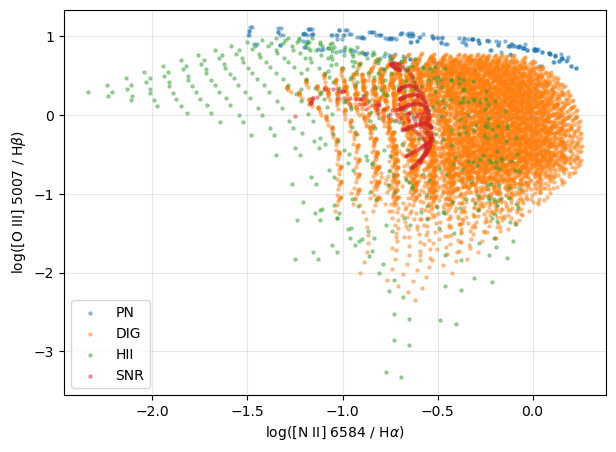

In [35]:
plt.figure(figsize=(7, 5))

for cls in class_order:
    sub = models_bpt[models_bpt["class"] == cls]
    plt.scatter(
        sub["log_NII_Ha"],
        sub["log_OIII_Hb"],
        s=5,
        alpha=0.4,
        label=cls,)

plt.xlabel(r"log([N II] 6584 / H$\alpha$)")
plt.ylabel(r"log([O III] 5007 / H$\beta$)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

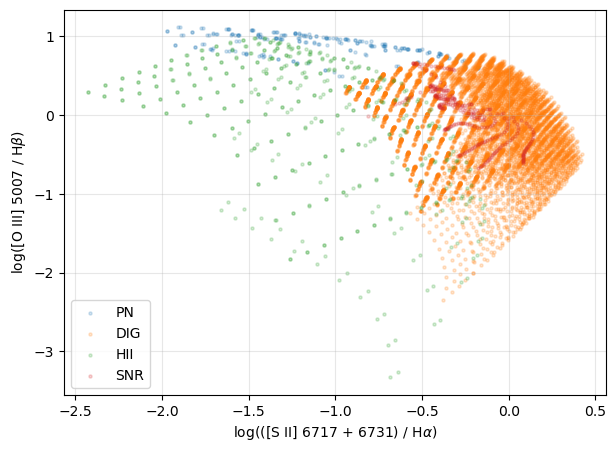

In [36]:
plt.figure(figsize=(7, 5))

for cls in class_order:
    sub = models_bpt[models_bpt["class"] == cls]
    plt.scatter(
        sub["log_SII_Ha"],
        sub["log_OIII_Hb"],
        s=5,
        alpha=0.2,
        label=cls,)

plt.xlabel(r"log(([S II] 6717 + 6731) / H$\alpha$)")
plt.ylabel(r"log([O III] 5007 / H$\beta$)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [37]:
models_bpt.to_csv("models_constrained_OI.csv", index=False)